# Waifu 3.0 フローセルの液置換

光軸での試料の入れ替わりを、**上面の濃度マップ、照射域を通る厚さ方向の断面、照射域と出口の置換曲線**で確認する。試作では1450 nm単波長の応答を確認済み。ここで示す値は、添付図面の Prototype 2 / Rev A と以下の条件に基づく計算値。

「条件設定と比較」にある数値または選択肢を変えて **計算する** を押す。計算後は結果の時刻をスライダーで移動できる。「サンプル計算」には0.34 mL/sでの実行例を収録した。

## 準備

このノートブックと `flowcell.py` を同じフォルダーに置く。専用カーネルを登録済みのPCでは **Python 3.11 (Flow Cell CUDA)** を選び、条件設定で **NVIDIA GPU / CUDA** を指定する。他の環境では Python 3.11 カーネルを選び、初回に必要なパッケージを導入する。

```python
%pip install numpy scipy matplotlib ipywidgets ipykernel
```

CUDA 12系の環境では GPU バックエンドも選択できる。対応する NVIDIA ドライバーと CUDA Toolkit が導入済みの場合は、下のパッケージを追加する。Toolkit をパッケージ経由で導入する場合は `cupy-cuda12x[ctk]` を指定する。インストール後にカーネルを再起動する。環境構成の詳細は [CuPyのインストール手順](https://docs.cupy.dev/en/stable/install.html) を参照。

```python
%pip install "cupy-cuda12x>=14,<15"
```

In [1]:
from dataclasses import replace
from itertools import product

from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, clear_output, display
from matplotlib.patches import Circle, Rectangle

from flowcell import GRIDS, Cell, Conditions, simulate, stable_window

try:
    import ipywidgets as widgets
except ImportError:
    widgets = None

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 図面と計算条件

- 測定室は **56.2 × 11.4 × 1.0 mm**。入口・出口は両短辺の中央、針は厚さ方向の中央を通る。ユーザー指定の外径 **0.7 mm**、内径 **0.5 mm**、金属部の長さ **24 mm** を使用する。根元と短辺外端が揃い、端部のランドが10 mmなので、室内へ14 mmずつ入る。容積は直方体で0.64068 mL、室内に突出した針の外形を引くと約0.630 mL。格子上の容積は結果欄に表示する。
- 照射域は測定室中央の直径 **2 mm**。照射域で厚さ方向と面内の濃度を平均する。縦置きでは入口から出口への方向を上下とし、水平ではガラス面に垂直な方向に重力を作用させる。
- 測定室と針内は、初めに旧液で満たされ、気泡はない。一定流量で入口針の根元に新液を入れ、針内の約 **4.71 µL** を流量で割った時間を入口遅れとして加える。針管内はプラグ流で近似する。時間の原点は入口針の根元での切替。出口曲線の観測点は室内の出口針先。
- 0〜100 vol% は20 °C基準のエタノール体積百分率。内部ではエタノール質量分率の切替前後を0・1に正規化して輸送する。同じ濃度を指定した場合は、濃度差のない仮想トレーサーの応答を表示する。密度・粘度は水とエタノールの二成分系の測定表を補間し、15–20 °Cは近接する温度行の傾きを使う。相互拡散係数は指定値を全域に適用する。

### モデルと判定

三次元の非圧縮流を直交スタガード格子で計算する。針の外形を固体マスク、先端開口を体積流量が一致する放物型の速度境界として表す。圧力射影法で流量を保存し、濃度は保存形の移流拡散方程式で進める。重力には組成に応じた密度を使い、慣性には旧液の密度を基準とする近似を使う。粘性項は局所動粘度と速度のラプラシアンの積で近似する。

**安定判定**は、照射域の新液指標が95%または99%以上になり、指定の保持時間を満たし、さらに計算終了まで下回らなかった区間を対象とする。表には区間の開始時刻と確認できた時刻を出す。時刻の分解能は濃度場の保存間隔に依存する。「未確認」には、閾値未到達と保持時間不足が含まれる。照射域の指標は光学的な置換の近似量であり、実機の安定判定には1450 nmの電圧応答との照合が必要。

`preview` は動作確認用の粗い格子、`standard` と `fine` は細分化用。針先の流れと濃度勾配は格子の影響を受ける。同じ条件で格子を比較し、照射域曲線や判定時刻の差を調べる。特に大きな濃度差では基準密度近似の誤差も大きくなり得る。物性の参照は [Khattab et al. の密度・粘度測定表](https://doi.org/10.1007/s11814-011-0239-6) と [Harris et al. の相互拡散測定](https://doi.org/10.1039/FT9938901969)。モデルの適用範囲は気泡のない水・エタノール系。糖や粒子、接着剤のフィレット、実際のシリンジの流量変動、流量停止後の保持は別途評価する。

## 条件設定と比較

形状例の「幅6 mm」と「出口を3 mm偏心」は、このノートブックで仮定した比較用形状。下の `LAYOUTS` で実際の図面寸法に差し替えられる。流量欄の数値に加え、追加流量をカンマ区切りで指定できる。

In [2]:
BASE_CELL = Cell()
BASE_CASE = Conditions()

LAYOUTS = {
    "V2 · drawing": BASE_CELL,
    "Example · 6 mm width": replace(BASE_CELL, width_mm=6.0),
    "Example · outlet offset": replace(BASE_CELL, outlet_offset_mm=3.0),
}
ORIENTATIONS = {"水平": "flat", "縦・入口が上": "inlet above", "縦・入口が下": "inlet below"}


def run_cases(case, layouts=("V2 · drawing",), orientations=("flat",),
              flows=None, grid="preview", backend="cpu", frame_interval_s=0.05, progress=None):
    flow_values = (case.flow_ml_s,) if flows is None else tuple(dict.fromkeys(flows))
    combinations = list(product(layouts, orientations, flow_values))
    if not combinations:
        raise ValueError("形状、向き、流量をそれぞれ1条件以上選んでください。")
    results = {}
    for i, (layout, orientation, flow) in enumerate(combinations, start=1):
        label = f"{layout} · {orientation} · {flow:g} mL/s"

        def report(simulated_s, total_s):
            if progress is not None:
                progress(i, len(combinations), label, simulated_s, total_s)

        results[label] = simulate(
            LAYOUTS[layout], replace(case, orientation=orientation, flow_ml_s=flow),
            grid, backend, frame_interval_s, time_progress=report if progress is not None else None)
    return results

### 曲線と濃度マップ

上面図は厚さ平均、断面図は照射域中心に最も近い幅方向位置のスライス。断面図の縦方向は拡大表示。色は比較中の全条件・全時刻で固定し、置換率 0–100% または入力した濃度の両端を色域に使う。

In [3]:
def summarize(results):
    header = (
        "| 条件 | 照射域 t95 開始 / 確認 [s] | 照射域 t99 開始 / 確認 [s] | "
        "t99 確認までの注入量 [mL] | 最終置換率 [%] |"
    )
    rows = [header, "|---|---:|---:|---:|---:|"]
    for label, result in results.items():
        case = result["conditions"]
        times, optical = result["time_s"], result["optical"]
        windows = [stable_window(times, optical, p, case.hold_s) for p in (0.95, 0.99)]
        stats = ["未確認" if window is None else f"{window[0]:.2f} / {window[1]:.2f}"
                 for window in windows]
        volume = "—" if windows[1] is None else f"{case.flow_ml_s * windows[1][1]:.3f}"
        rows.append(f"| {label} | {stats[0]} | {stats[1]} | {volume} | {100 * optical[-1]:.1f} |")
    display(Markdown("\n".join(rows)))


def draw(results, selected, time_s, quantity="replacement"):
    result = results[selected]
    cell = result["cell"]
    frame = np.argmin(np.abs(result["time_s"] - time_s))
    frame_time = result["time_s"][frame]
    field = result["fields"][frame]
    counts = np.isfinite(field).sum(axis=0)
    depth_mean = np.divide(np.nansum(field, axis=0), counts,
                           out=np.full(counts.shape, np.nan), where=counts > 0)
    beam_x = cell.length_mm / 2 + cell.beam_offset_x_mm
    beam_y = cell.width_mm / 2 + cell.beam_offset_y_mm
    centers_y = (np.arange(field.shape[1]) + 0.5) * cell.width_mm / field.shape[1]
    section = field[:, np.argmin(abs(centers_y - beam_y)), :]
    if quantity == "abv":
        intervals = [(r["conditions"].before_abv, r["conditions"].after_abv) for r in results.values()]
        low, high = min(map(min, intervals)), max(map(max, intervals))
        if high == low:
            low, high = 0, 100
        before, after = result["mass_endpoints"]

        def color_value(values):
            return np.interp(before + (after - before) * values,
                             result["abv_mass_axis"], result["abv_values"])

        color_label = "Ethanol concentration [vol% at 20 °C]"
    else:
        low, high = 0, 100

        def color_value(values):
            return 100 * values

        color_label = "New-sample fraction [%]"

    fig, (curves, top, section_plot) = plt.subplots(
        3, 1, figsize=(10.5, 8.3), height_ratios=(2.0, 1.28, 1), layout="constrained")
    for label, run in results.items():
        curves.plot(run["time_s"], 100 * run["optical"], label=f"Optical · {label}",
                    alpha=1 if label == selected else 0.65)
    curves.plot(result["time_s"], 100 * result["outlet_tip"], "--", color="0.38",
                label="Outlet tip · selected case")
    for threshold in (95, 99):
        curves.axhline(threshold, color="0.68", linewidth=0.75, linestyle=":")
    curves.axvline(frame_time, color="0.22", linewidth=1)
    curves.set(xlabel="Time since sample switch at needle root [s]", ylabel="Replacement [%]",
               ylim=(-3, 105))
    curves.legend(loc="lower right", fontsize=8)

    cmap = plt.colormaps["viridis"].with_extremes(bad="#cbd5e1")
    extent_xy = (0, cell.length_mm, 0, cell.width_mm)
    extent_xz = (0, cell.length_mm, 0, cell.gap_mm)
    common = dict(origin="lower", cmap=cmap, vmin=low, vmax=high, interpolation="nearest")
    image = top.imshow(color_value(depth_mean), extent=extent_xy, aspect="equal", **common)
    section_plot.imshow(color_value(section), extent=extent_xz, aspect="auto", **common)
    for x_tip, width, offset in (
        (0, result["inlet_tip_x_mm"], cell.inlet_offset_mm),
        (result["outlet_tip_x_mm"], cell.length_mm - result["outlet_tip_x_mm"], cell.outlet_offset_mm),
    ):
        top.add_patch(Rectangle((x_tip, (cell.width_mm - cell.needle_od_mm) / 2 + offset),
                                width, cell.needle_od_mm, fill=False, ec="white", lw=0.85))
    top.axhline(beam_y, color="white", alpha=0.65, linestyle=":", linewidth=0.8)
    top.add_patch(Circle((beam_x, beam_y), cell.beam_diameter_mm / 2,
                         fill=False, ec="#ff8657", lw=1.6))
    half_beam = cell.beam_diameter_mm / 2
    section_plot.axvspan(beam_x - half_beam, beam_x + half_beam,
                         facecolor="none", edgecolor="#ff8657", linewidth=1.35)
    top.set(title=f"Depth-averaged XY map · t = {frame_time:.2f} s", ylabel="Width y [mm]")
    section_plot.set(title="XZ section through optical region · z exaggerated",
                     xlabel="Distance from inner inlet wall x [mm]", ylabel="Gap z [mm]")
    fig.colorbar(image, ax=[top, section_plot], label=color_label, shrink=0.92)
    return fig


def show_figure(results, label, time_s, quantity="replacement"):
    fig = draw(results, label, time_s, quantity)
    display(fig)
    plt.close(fig)


def view_results(results):
    summarize(results)
    label = next(iter(results))
    if widgets is None:
        show_figure(results, label, 0.5)
        return
    case = widgets.Dropdown(options=list(results), description="表示条件",
                            layout=widgets.Layout(width="640px"))
    step = min(float(np.diff(r["time_s"]).min()) for r in results.values())
    end = max(float(r["time_s"][-1]) for r in results.values())
    time_at = widgets.FloatSlider(value=min(0.5, end), min=0, max=end, step=step,
                                  description="時刻 [s]", continuous_update=False,
                                  readout_format=".2f", layout=widgets.Layout(width="520px"))
    color = widgets.Dropdown(options=[("試料置換率 [%]", "replacement"),
                                       ("エタノール濃度 [vol%]", "abv")], description="色尺度")
    output = widgets.interactive_output(
        lambda selected, time_s, quantity: show_figure(results, selected, time_s, quantity),
        {"selected": case, "time_s": time_at, "quantity": color})
    display(widgets.VBox([case, time_at, color, output]))

In [4]:
def configure():
    if widgets is None:
        print("ipywidgets が未導入です。BASE_CASE またはサンプル計算の条件を変更して実行できます。")
        return

    style = {"description_width": "140px"}

    def slider(label, value, low, high, step, fmt):
        return widgets.FloatSlider(description=label, value=value, min=low, max=high, step=step,
                                   readout_format=fmt, style=style, continuous_update=False,
                                   layout=widgets.Layout(width="520px"))

    before = slider("切替前 [vol%]", BASE_CASE.before_abv, 0, 100, 0.5, ".1f")
    after = slider("切替後 [vol%]", BASE_CASE.after_abv, 0, 100, 0.5, ".1f")
    temperature = slider("液温 [°C]", BASE_CASE.temperature_c, 15, 35, 0.5, ".1f")
    flow = slider("流量 [mL/s]", BASE_CASE.flow_ml_s, 0.02, 1.5, 0.01, ".2f")
    extra = widgets.Text(description="追加流量 [mL/s]", placeholder="例 0.20, 0.50", style=style)
    injected = widgets.FloatText(description="注入量 [mL]", value=BASE_CASE.injected_ml, style=style)
    hold = widgets.FloatText(description="保持時間 [s]", value=BASE_CASE.hold_s, style=style)
    resolution = widgets.Dropdown(options=list(GRIDS), description="格子", style=style)
    device = widgets.Dropdown(options=[("CPU", "cpu"), ("NVIDIA GPU / CUDA", "cuda")],
                              description="計算装置", style=style)
    orientation = widgets.SelectMultiple(options=list(ORIENTATIONS.items()), value=("flat",),
                                         description="置き方", rows=3, style=style)
    layout = widgets.SelectMultiple(options=list(LAYOUTS), value=("V2 · drawing",),
                                    description="形状", rows=len(LAYOUTS), style=style)
    status = widgets.HTML()
    run_button = widgets.Button(description="計算する", button_style="primary")
    pictures = widgets.Output()

    def run_clicked(_):
        run_button.disabled = True
        status.value = "計算中"
        try:
            case = replace(BASE_CASE, before_abv=before.value, after_abv=after.value,
                           temperature_c=temperature.value, flow_ml_s=flow.value,
                           injected_ml=injected.value, hold_s=hold.value)
            flows = [flow.value] + [float(v.strip()) for v in extra.value.split(",") if v.strip()]

            def progress(number, cases, label, simulated_s, total_s):
                status.value = (f"{number} / {cases}　{label}　{100 * simulated_s / total_s:.2f}%"
                                f"　計算時刻 {simulated_s:.4f} / {total_s:.4f} s")

            results = run_cases(case, layout.value, orientation.value, flows,
                                resolution.value, device.value, progress=progress)
            total_s = sum(item["runtime_s"] for item in results.values())
            status.value = f"{len(results)} 条件の計算完了（{total_s:.1f} 秒）"
            with pictures:
                clear_output(wait=True)
                view_results(results)
        except (ValueError, RuntimeError, KeyError) as error:
            status.value = "計算条件または実行環境を確認してください"
            with pictures:
                clear_output(wait=True)
                print(error)
        finally:
            run_button.disabled = False

    run_button.on_click(run_clicked)
    display(widgets.VBox([
        before, after, temperature, flow, extra, widgets.HBox([injected, hold]),
        orientation, layout, resolution, device, run_button, status, pictures,
    ]))


configure()

## サンプル計算

図面のV2、水平、蒸留水から10 vol%、20 °C、0.34 mL/s、1.5 mL注入。`preview` の実行例。セルを実行し直す場合は計算時間がかかる。複数条件をコードで回すには、下の `run_cases` の `orientations` や `flows` を変更する。

| 条件 | 照射域 t95 開始 / 確認 [s] | 照射域 t99 開始 / 確認 [s] | t99 確認までの注入量 [mL] | 最終置換率 [%] |
|---|---:|---:|---:|---:|
| V2 · drawing · flat · 0.34 mL/s | 未確認 | 未確認 | — | 66.6 |

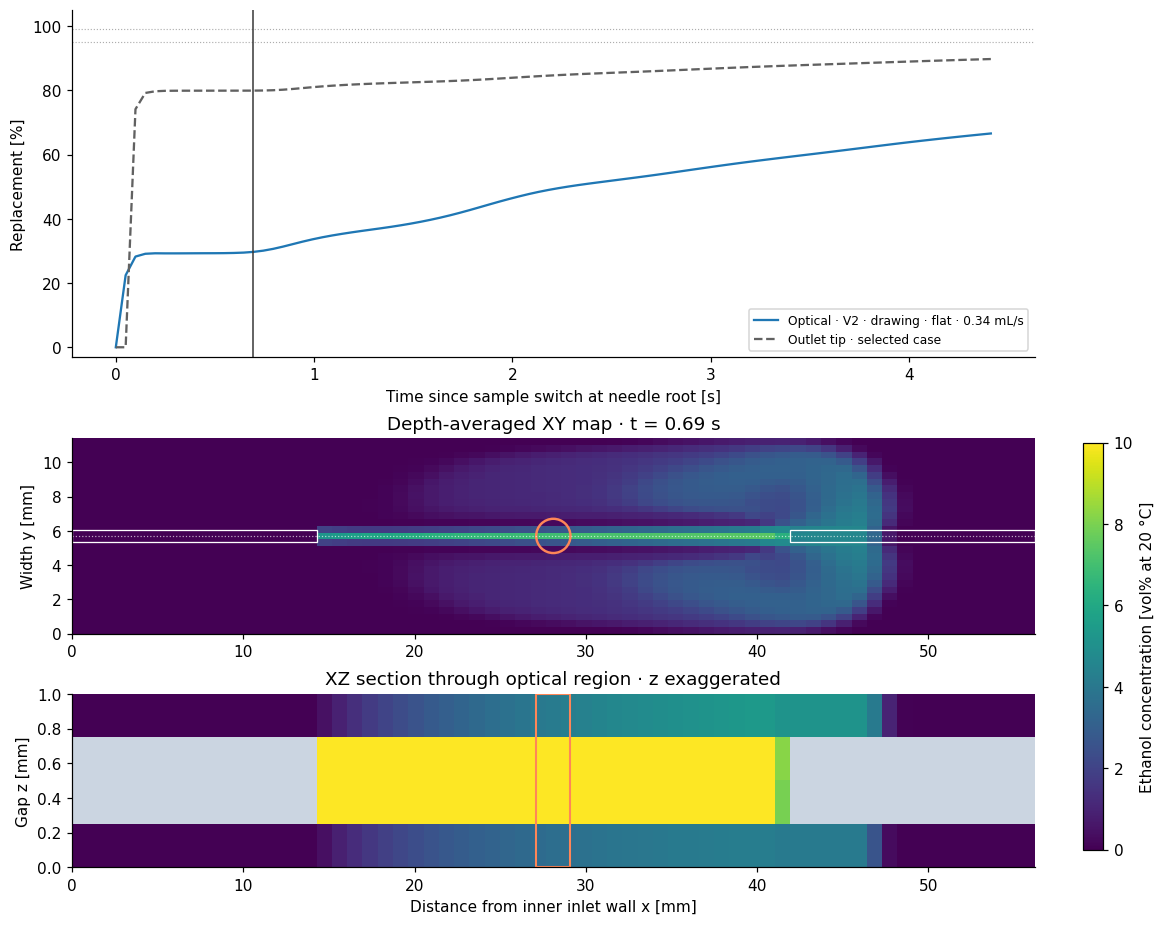

Grid chamber volume: 0.624 mL
Inlet needle delay: 0.0139 s
Relative tracer balance error: 1.27e-15
Largest final fluid-cell divergence: 6.37e-12 s⁻¹


In [9]:
example = run_cases(BASE_CASE)
case_label, example_result = next(iter(example.items()))
summarize(example)
show_figure(example, case_label, 0.70, quantity="abv")

print(f"Grid chamber volume: {example_result['volume_ml']:.3f} mL")
print(f"Inlet needle delay: {example_result['needle_delay_s']:.4f} s")
print(f"Relative tracer balance error: {example_result['mass_balance_error']:.2e}")
print(f"Largest final fluid-cell divergence: {example_result['max_divergence_s_inv']:.2e} s⁻¹")

In [5]:
print(BASE_CELL.width_mm)

2.0
